# Lab 1 — Task 2: Regression Modeling of Bitcoin Next-Day Close

This is a **standalone English version of Task 2** from the final group notebook.

## What this notebook does

1. Downloads and cleans the same Kaggle Bitcoin OHLCV dataset.
2. Defines a real forecasting target:

   **Target on day t = Closing price on day t + 1**

3. Uses only information available by the end of the current day.
4. Splits the data chronologically into training and hold-out test periods.
5. Trains Ordinary Least Squares (OLS) linear regression.
6. Evaluates OLS using RMSE, MAE, and R².
7. Removes training outliers using the Tukey IQR rule on next-day log return.
8. Standardizes features and trains Ridge regression in an sklearn `Pipeline`.
9. Chooses Ridge `alpha` with `TimeSeriesSplit`.
10. Compares Ridge, OLS, and a naive time-series baseline.



- **ŷ** = predicted value
- **y** = actual value
- **b** = intercept
- **w₁, w₂, ...** = model coefficients
- **x₁, x₂, ...** = predictor values
- **Σ** = sum
- **√** = square root
- **α** = Ridge regularization strength
- **μ** = mean
- **σ** = standard deviation

The notebook is designed so that **Task 2 can be run independently** from Task 1.


In [1]:
%pip install -q kagglehub pandas numpy scipy scikit-learn seaborn matplotlib



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


> **Output note:** The outputs saved in this notebook were taken from the successfully executed **final group notebook** using the same Task 2 calculations and Kaggle dataset. The current environment used to prepare this English copy does not have outbound Kaggle access, so the Kaggle download itself could not be re-run here. If you run this notebook in your normal Jupyter environment with internet access, it will download the Kaggle dataset and recompute the cells.


## 0. Imports and dataset download

We use the public Kaggle dataset:

**Bitcoin Prices Dataset (2010–2026)**  
`amineipad/bitcoin-prices-dataset`

`kagglehub.dataset_download()` downloads the latest available dataset version.


In [2]:
from pathlib import Path
import re
import warnings

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')

# Download the latest dataset version.
path = kagglehub.dataset_download("amineipad/bitcoin-prices-dataset")
print("Kaggle dataset directory:", path)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 163k/163k [00:00<00:00, 543kB/s]

Extracting files...
Kaggle dataset directory: /Users/moladoe/.cache/kagglehub/datasets/amineipad/bitcoin-prices-dataset/versions/1


## 1. Load and clean the OHLCV data

The code searches the Kaggle download directory for a CSV containing the required fields:

- `Date`
- `Open`
- `High`
- `Low`
- `Close`
- `Volume`

The data are converted to suitable numeric and datetime types, sorted chronologically, and checked for basic OHLCV consistency.


In [3]:
def _norm_name(name: str) -> str:
    return re.sub(r'[^a-z0-9]+', '', str(name).strip().lower())

aliases = {
    'Date': {'date', 'datetime', 'timestamp', 'time'},
    'Open': {'open', 'openprice', '24open'},
    'High': {'high', 'highprice', '24high'},
    'Low': {'low', 'lowprice', '24low'},
    'Close': {'close', 'closeprice', 'closingprice'},
    'Volume': {'volume', 'vol', 'tradingvolume', '24hvolume'},
}

csv_files = sorted(Path(path).rglob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f"No CSV files were found in {path!r}")

selected_file = None
rename_map = None

for file in csv_files:
    try:
        sample = pd.read_csv(file, nrows=5)
    except Exception:
        continue

    normalized = {_norm_name(c): c for c in sample.columns}
    current_map = {}
    ok = True

    for canonical, variants in aliases.items():
        match = next((normalized[v] for v in variants if v in normalized), None)
        if match is None:
            ok = False
            break
        current_map[match] = canonical

    if ok:
        selected_file = file
        rename_map = current_map
        break

if selected_file is None:
    print("CSV files found:")
    for f in csv_files:
        print(" -", f)
    raise ValueError(
        "Could not find a CSV containing Date/Timestamp, Open, High, Low, Close, and Volume."
    )

raw = pd.read_csv(selected_file).rename(columns=rename_map)
df = raw[['Date', 'Open', 'High', 'Low', 'Close', 'Volume']].copy()

# Convert Date/Timestamp to datetime.
if pd.api.types.is_numeric_dtype(df['Date']):
    med = pd.to_numeric(df['Date'], errors='coerce').median()
    if med > 1e14:
        unit = 'ns'
    elif med > 1e11:
        unit = 'ms'
    elif med > 1e8:
        unit = 's'
    else:
        unit = None
    df['Date'] = pd.to_datetime(df['Date'], unit=unit, errors='coerce', utc=True)
else:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce', utc=True)

df['Date'] = df['Date'].dt.tz_convert(None)

# Convert OHLCV fields to numeric values.
for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '', regex=False).str.strip(),
        errors='coerce'
    )

before = len(df)

df = (
    df.dropna(subset=['Date', 'Open', 'High', 'Low', 'Close', 'Volume'])
      .drop_duplicates(subset='Date', keep='last')
      .sort_values('Date')
      .reset_index(drop=True)
)

# Basic OHLCV validity checks.
valid = (
    (df[['Open', 'High', 'Low', 'Close']] > 0).all(axis=1)
    & (df['Volume'] >= 0)
    & (df['High'] >= df[['Open', 'Close', 'Low']].max(axis=1))
    & (df['Low'] <= df[['Open', 'Close', 'High']].min(axis=1))
)

invalid_count = int((~valid).sum())
df = df.loc[valid].reset_index(drop=True)

if len(df) < 100:
    raise ValueError(f"Only {len(df)} rows remain after cleaning; at least 100 are required.")

print("File used:", selected_file)
print(f"Rows before cleaning: {before:,}; after cleaning: {len(df):,}")
print(f"Rows removed for invalid OHLCV relationships: {invalid_count:,}")
print("Period:", df['Date'].min().date(), "—", df['Date'].max().date())

display(df.head())
display(df.describe(include='all'))


File used: bitcoin.csv
Rows before cleaning: 5,883; after cleaning: 5,883
Rows removed for invalid OHLCV relationships: 0
Period: 2010-01-01 — 2026-02-08


,Date,Open,High,Low,Close,Volume
0,2010-01-01,0.3000,0.3034,0.2955,0.3000,715.8000
1,2010-01-02,0.3000,0.3044,0.2995,0.3000,"2,028.3000"
2,2010-01-03,0.3000,0.3037,0.2959,0.3000,273.0000
3,2010-01-04,0.3000,0.3034,0.2985,0.3000,"1,452.0000"
4,2010-01-05,0.3000,0.3027,0.2963,0.3000,"1,002.6000"


,Date,Open,High,Low,Close,Volume
count,5883,"5,883.0000","5,883.0000","5,883.0000","5,883.0000","5,883.0000"
mean,2018-01-20 00:00:00,"21,725.0511","21,973.7162","21,487.5762","21,736.7798","108,791,503.1032"
min,2010-01-01 00:00:00,0.3000,0.3003,0.2940,0.3000,30.3000
25%,2014-01-10 12:00:00,430.5700,431.2114,422.1345,430.5700,"1,271,205.3150"
50%,2018-01-20 00:00:00,"7,193.6000","7,207.9790","7,057.9718","7,193.6000","17,568,092.4000"
75%,2022-01-29 12:00:00,"42,265.1900","42,370.1357","41,483.5788","42,265.1900","130,229,682.1050"
max,2026-02-08 00:00:00,"93,429.2000","95,281.0119","93,326.4455","93,429.2000","932,516,845.2000"
std,NaN,"30,114.9787","30,445.2565","29,793.0298","30,119.9523","185,109,840.6663"


## 2. Leakage-safe chronological split

Because this is time-series data, observations are **not randomly shuffled**.

The final 20% of the raw timeline are reserved as the hold-out period.  
This creates a cutoff date that will also be used for Task 2.

The idea is:

**past → training → future → test**

This reduces the risk of **look-ahead leakage**.


In [4]:
split_idx = int(len(df) * 0.80)
train_raw = df.iloc[:split_idx].copy()
holdout_raw = df.iloc[split_idx:].copy()
split_date = train_raw['Date'].max()

print(f"Training period ends on: {split_date.date()}")
print(f"Raw train rows: {len(train_raw):,}")
print(f"Raw hold-out rows: {len(holdout_raw):,}")
print(f"Hold-out begins on: {holdout_raw['Date'].min().date()}")


Training period ends on: 2022-11-19
Raw train rows: 4,706
Raw hold-out rows: 1,177
Hold-out begins on: 2022-11-20


# Task 2 [4 points]

The assignment requires:

1. Choose a target and predictors, justify them, and analyze them without using future hold-out information.
2. Train a linear regression model without regularization and evaluate it using **RMSE, MAE, and R²**.
3. Train a regularized linear model, remove outliers, normalize the predictors, justify those preprocessing choices, use an sklearn `Pipeline`, and evaluate it using **RMSE, MAE, and R²**.


## 2.1 Target, predictors, and forecasting setup

To make the problem a real forecasting task, we define the target as:

**Target on day t = Close on day t + 1**

In simple words:

**Today's information → predict tomorrow's closing price**

### Predictors

- `Open` — opening price of the current day
- `High` — highest price of the current day
- `Low` — lowest price of the current day
- `Close` — closing price of the current day
- `LogVolume` — calculated as **ln(1 + Volume)**. This reduces the effect of the very large scale and right-skewness of trading volume.
- `LogReturn_1d` — current one-day logarithmic return:

  **LogReturn today = ln[ Close(today) / Close(yesterday) ]**

- `RangePct` — relative intraday trading range:

  **RangePct = (High − Low) / Close**

- `SMA_7` — 7-day simple moving average:

  **SMA₇ = average of the current Close and the previous 6 Close values**

- `SMA_30` — 30-day simple moving average:

  **SMA₃₀ = average of the current Close and the previous 29 Close values**

The moving-average features use only the current and previous days.

No predictor uses information from tomorrow, which is the target day.


In [5]:
model_df = df.copy()

# Feature engineering.
model_df['LogVolume'] = np.log1p(model_df['Volume'].clip(lower=0))
model_df['LogReturn_1d'] = np.log(
    model_df['Close'] / model_df['Close'].shift(1)
)
model_df['RangePct'] = (
    (model_df['High'] - model_df['Low']) / model_df['Close']
)
model_df['SMA_7'] = model_df['Close'].rolling(7).mean()
model_df['SMA_30'] = model_df['Close'].rolling(30).mean()

# Next-day target.
model_df['Target_Close_Next_Day'] = model_df['Close'].shift(-1)
model_df['TargetDate'] = model_df['Date'].shift(-1)

features = [
    'Open',
    'High',
    'Low',
    'Close',
    'LogVolume',
    'LogReturn_1d',
    'RangePct',
    'SMA_7',
    'SMA_30'
]

target = 'Target_Close_Next_Day'

# Remove rows where rolling calculations or shifts create NaN values.
model_df = (
    model_df.replace([np.inf, -np.inf], np.nan)
            .dropna(subset=features + [target, 'TargetDate'])
            .reset_index(drop=True)
)

# IMPORTANT:
# Split by TARGET DATE so that no y_train belongs after the cutoff date.
train_model = model_df[model_df['TargetDate'] <= split_date].copy()
test_model = model_df[model_df['TargetDate'] > split_date].copy()

X_train = train_model[features]
y_train = train_model[target]

X_test = test_model[features]
y_test = test_model[target]

print(
    'Train predictors:',
    train_model['Date'].min().date(),
    '—',
    train_model['Date'].max().date()
)
print(
    'Train targets:   ',
    train_model['TargetDate'].min().date(),
    '—',
    train_model['TargetDate'].max().date()
)
print(
    'Test predictors: ',
    test_model['Date'].min().date(),
    '—',
    test_model['Date'].max().date()
)
print(
    'Test targets:    ',
    test_model['TargetDate'].min().date(),
    '—',
    test_model['TargetDate'].max().date()
)
print('Shapes:', X_train.shape, X_test.shape)


Train predictors: 2010-01-30 — 2022-11-18
Train targets:    2010-01-31 — 2022-11-19
Test predictors:  2022-11-19 — 2026-02-07
Test targets:     2022-11-20 — 2026-02-08
Shapes: (4676, 9) (1177, 9)


### Training-only exploratory analysis

To avoid using hold-out information for modeling decisions, the following correlation matrix and scatterplot are calculated **only from the training period**.


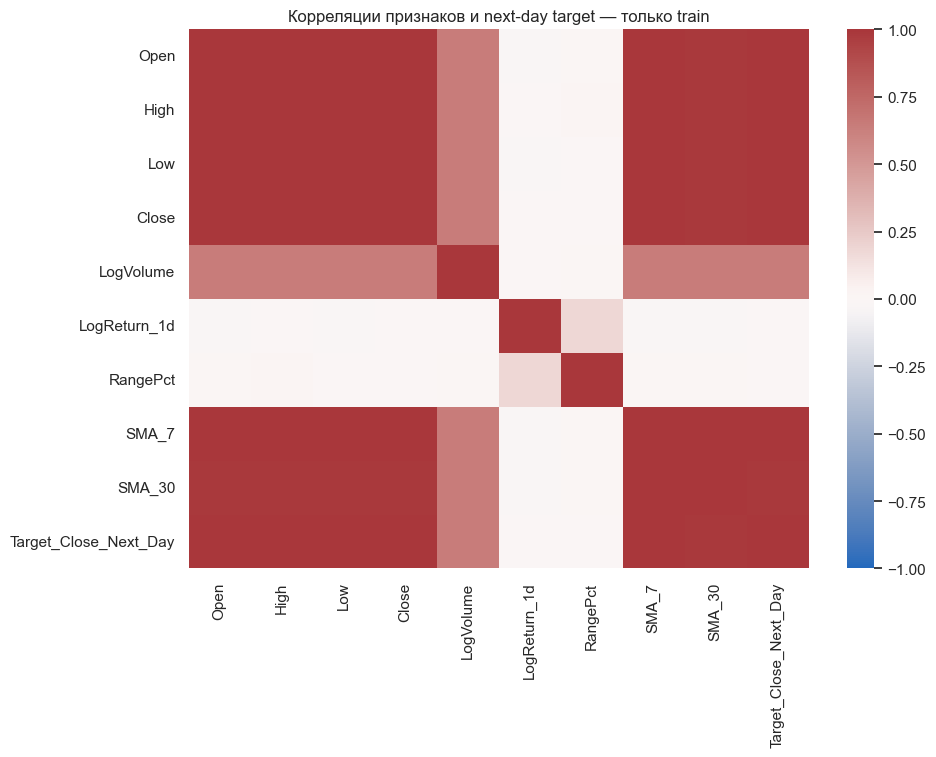

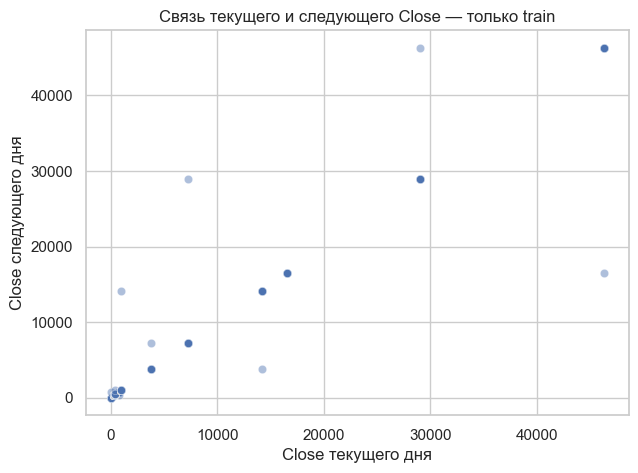

In [6]:
train_analysis = X_train.copy()
train_analysis['Target_Close_Next_Day'] = y_train.to_numpy()

plt.figure(figsize=(10, 7))
sns.heatmap(
    train_analysis.corr(),
    cmap='vlag',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Feature and next-day target correlations — training data only')
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(
    x=X_train['Close'],
    y=y_train,
    alpha=0.45
)
plt.xlabel('Current-day Close')
plt.ylabel('Next-day Close')
plt.title('Current Close vs next-day Close — training data only')
plt.show()


### Conclusion for Part 2.1

The forecasting moment is defined clearly:

**After the current day closes, the model predicts the closing price of the next day.**

The hold-out period is not used to create or select predictors. This reduces the risk of **look-ahead leakage**.

The current-day price variables are expected to be strongly correlated with one another. This makes Ridge regularization worth testing, although regularization is **not guaranteed** to improve test performance.


## 2.2 Ordinary Least Squares linear regression

### Linear regression model

The model predicts the target using an intercept plus weighted predictor values:

**Predicted y = b + w₁×x₁ + w₂×x₂ + ... + wₚ×xₚ**

For this lab, that means the predicted next-day Bitcoin closing price is calculated from the selected predictors and their learned coefficients.

### What OLS minimizes

OLS chooses the coefficients that make the squared prediction errors as small as possible:

**OLS loss = Σ (Actual value − Predicted value)²**

### Scaling

We use `StandardScaler` for OLS as well.

Scaling is **not regularization**. It only changes the numerical scale of the predictors. This improves numerical conditioning and makes the preprocessing of OLS and Ridge more comparable.

## Evaluation metrics

### RMSE — Root Mean Squared Error

**RMSE = √[ (1 / n) × Σ(Actual − Predicted)² ]**

Interpretation:
- Lower is better.
- Large errors receive extra weight because the errors are squared.
- RMSE has the same unit as the target.

### MAE — Mean Absolute Error

**MAE = (1 / n) × Σ|Actual − Predicted|**

Interpretation:
- Lower is better.
- It is the average absolute prediction error.
- MAE is less sensitive to a few very large errors than RMSE.

### R² — Coefficient of Determination

**R² = 1 − [ Σ(Actual − Predicted)² / Σ(Actual − Mean of Actual)² ]**

Interpretation:
- **R² = 1** → perfect fit.
- **R² ≈ 0** → roughly similar to predicting the mean.
- **R² < 0** → worse than predicting the mean.
- A high R² is **not the same thing as prediction accuracy**.


In [7]:
def metrics_dict(y_true, y_pred):
    return {
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'R2': float(r2_score(y_true, y_pred)),
    }

# OLS model with the same scaling concept later used for Ridge.
ols_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

ols_pipe.fit(X_train, y_train)

ols_train_pred = ols_pipe.predict(X_train)
ols_test_pred = ols_pipe.predict(X_test)

ols_metrics = pd.DataFrame([
    {
        'Model': 'OLS',
        'Split': 'Train',
        **metrics_dict(y_train, ols_train_pred)
    },
    {
        'Model': 'OLS',
        'Split': 'Test',
        **metrics_dict(y_test, ols_test_pred)
    },
])

display(ols_metrics)

# Naive time-series baseline:
# tomorrow's Close is assumed to equal today's Close.
naive_test_pred = X_test['Close'].to_numpy()

print(
    'Naive test metrics:',
    metrics_dict(y_test, naive_test_pred)
)


,Model,Split,RMSE,MAE,R2
0,OLS,Train,646.4393,35.4570,0.9978
1,OLS,Test,"1,765.7726",168.8844,0.9948


Naive test metrics: {'RMSE': 1762.6308509359517, 'MAE': 86.07553101104503, 'R2': 0.9948353794472584}


### Why include a naive baseline?

Bitcoin prices are strongly persistent from one day to the next.

Therefore we compare the models with a very simple rule:

**Predicted Close tomorrow = Close today**

This is called the **naive persistence baseline**.

Because today's and tomorrow's prices are usually close to one another, this simple rule can already produce a very high R².

Therefore, a high R² by itself does not prove that a more complicated model adds useful forecasting value.


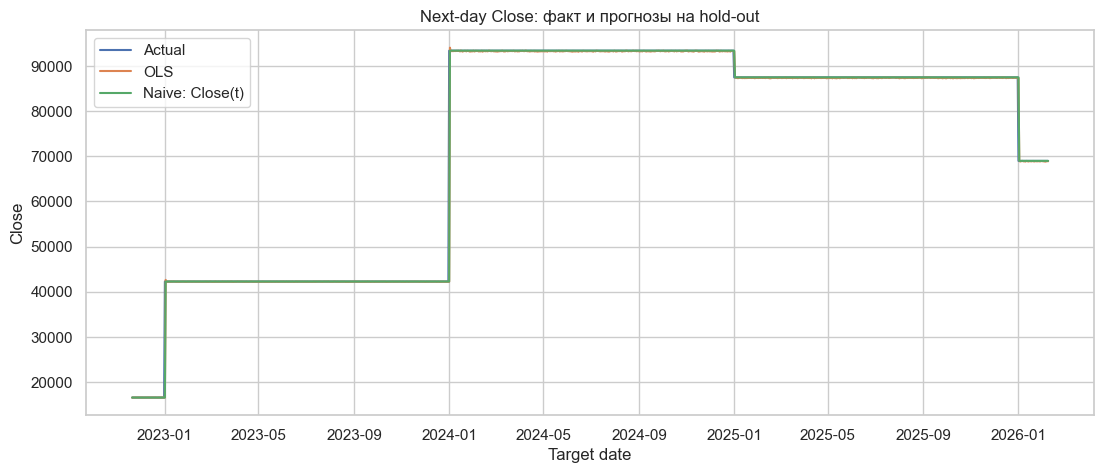

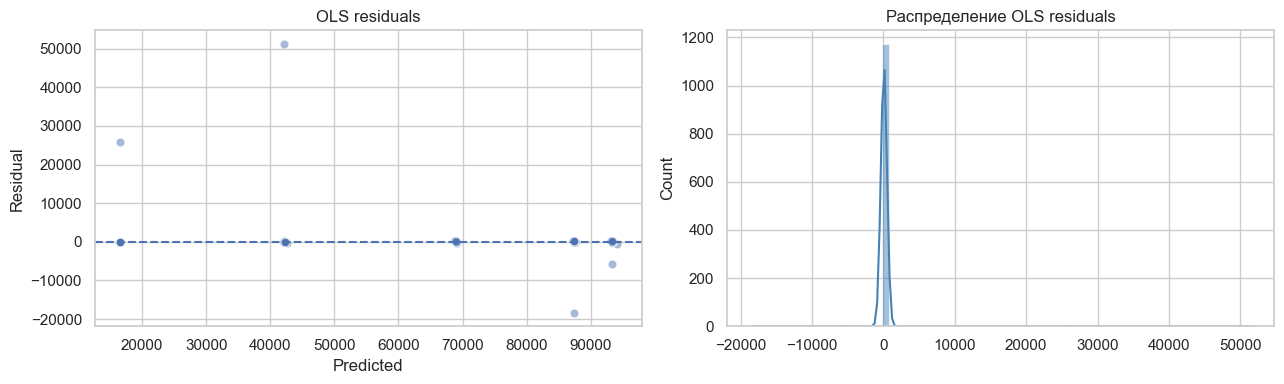

In [8]:
plot_test = test_model[['TargetDate']].copy()
plot_test['Actual'] = y_test.to_numpy()
plot_test['OLS'] = ols_test_pred
plot_test['Naive'] = naive_test_pred

plt.figure(figsize=(13, 5))
plt.plot(
    plot_test['TargetDate'],
    plot_test['Actual'],
    label='Actual'
)
plt.plot(
    plot_test['TargetDate'],
    plot_test['OLS'],
    label='OLS'
)
plt.plot(
    plot_test['TargetDate'],
    plot_test['Naive'],
    label='Naive: Close(t)'
)
plt.title('Next-day Close: actual values and hold-out predictions')
plt.xlabel('Target date')
plt.ylabel('Close')
plt.legend()
plt.show()

# Residual = actual - predicted
ols_residuals = y_test.to_numpy() - ols_test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.scatterplot(
    x=ols_test_pred,
    y=ols_residuals,
    alpha=0.5,
    ax=axes[0]
)
axes[0].axhline(0, linestyle='--')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Residual')
axes[0].set_title('OLS residuals')

sns.histplot(
    ols_residuals,
    kde=True,
    color='steelblue',
    ax=axes[1]
)
axes[1].set_title('Distribution of OLS residuals')

plt.tight_layout()
plt.show()


### Conclusion for Part 2.2

OLS quality must be judged using the printed **RMSE, MAE, and R²** values and by comparing them with the naive baseline.

For a persistent time series, even a very simple baseline can produce a very high R². Therefore, **R² alone is not enough** to show that a forecasting model provides a meaningful improvement.

Residual plots are also inspected because they show where and how the model makes prediction errors.


## 2.3 Ridge regression + outlier removal + standardization + Pipeline

## A. Outlier removal

Removing outliers based only on the **absolute Bitcoin price** would be inappropriate because Bitcoin has a strong long-term trend.

For example, a very high Bitcoin price in a later year is not automatically an abnormal observation.

Therefore, outlier detection is applied to the **next-day logarithmic return** in the training set:

**Next-day log return = ln[ Close(t + 1) / Close(t) ]**

### Tukey IQR rule

First calculate:

**Q₁ = 25th percentile**

**Q₃ = 75th percentile**

Then:

**IQR = Q₃ − Q₁**

The lower and upper outlier limits are:

**Lower limit = Q₁ − 1.5 × IQR**

**Upper limit = Q₃ + 1.5 × IQR**

Values outside these limits are treated as potential outliers.

The limits are calculated **only from the training set**. Test observations are never removed.

---

## B. Standardization

`StandardScaler` transforms each predictor using:

**Standardized value z = (x − μ) / σ**

where:

- **x** = original predictor value
- **μ** = training mean of that predictor
- **σ** = training standard deviation of that predictor

After standardization, predictors are placed on comparable numerical scales.

This is especially important for Ridge because the L2 penalty depends on coefficient size.

---

## C. Ridge regression

Ordinary OLS minimizes:

**OLS loss = Σ(Actual − Predicted)²**

Ridge minimizes:

**Ridge loss = Σ(Actual − Predicted)² + α × Σ(w²)**

The second part is the **L2 regularization penalty**.

It discourages excessively large model coefficients and can improve numerical stability when predictors are strongly correlated.

### Meaning of alpha

- **α = 0** → approximately ordinary linear regression
- **Small α** → weak regularization
- **Large α** → strong regularization

Too much regularization can cause underfitting.

---

## D. Selecting alpha

`alpha` is selected only from training data using `TimeSeriesSplit`.

Time-series cross-validation keeps chronological order:

**Past training data → later validation data**

It does not use future observations to validate predictions about the past.


In [9]:
# Standard IQR rule applied to next-day log return — training data only.
train_next_return = np.log(
    y_train.to_numpy() / X_train['Close'].to_numpy()
)
train_next_return = pd.Series(
    train_next_return,
    index=X_train.index
)

q1 = train_next_return.quantile(0.25)
q3 = train_next_return.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

keep_mask = train_next_return.between(lower, upper)

X_train_clean = X_train.loc[keep_mask].copy()
y_train_clean = y_train.loc[keep_mask].copy()

print(f'Q1 = {q1:.6f}')
print(f'Q3 = {q3:.6f}')
print(f'IQR = {iqr:.6f}')
print(f'Outlier bounds: [{lower:.6f}, {upper:.6f}]')
print(
    f'Removed from training data: {(~keep_mask).sum():,} '
    f'of {len(keep_mask):,} ({(~keep_mask).mean():.2%})'
)


Q1 = 0.000000
Q3 = 0.000000
IQR = 0.000000
Outlier bounds: [0.000000, 0.000000]
Removed from training data: 12 of 4,676 (0.26%)


In [10]:
# StandardScaler + Ridge are kept together in one Pipeline.
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

# Candidate regularization strengths.
alphas = np.logspace(-4, 4, 41)

# Time-series-aware cross-validation.
tscv = TimeSeriesSplit(n_splits=5)

ridge_search = GridSearchCV(
    estimator=ridge_pipe,
    param_grid={'ridge__alpha': alphas},
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    refit=True,
)

ridge_search.fit(X_train_clean, y_train_clean)

ridge_best = ridge_search.best_estimator_

ridge_train_pred = ridge_best.predict(X_train_clean)
ridge_test_pred = ridge_best.predict(X_test)

print(
    'Best alpha:',
    ridge_search.best_params_['ridge__alpha']
)

ridge_metrics = pd.DataFrame([
    {
        'Model': 'Ridge',
        'Split': 'Train (clean)',
        **metrics_dict(y_train_clean, ridge_train_pred)
    },
    {
        'Model': 'Ridge',
        'Split': 'Test',
        **metrics_dict(y_test, ridge_test_pred)
    },
])

display(ridge_metrics)


Best alpha: 0.0001


,Model,Split,RMSE,MAE,R2
0,Ridge,Train(clean),0.0335,0.0153,1.0000
1,Ridge,Test,"1,762.6284",86.1944,0.9948


### Fair comparison of regularization

If Ridge is trained on an outlier-cleaned training set while OLS is trained on the full training set, the difference between them could come from either:

1. regularization, or
2. outlier removal.

To separate these effects, we also train OLS on the **same cleaned training set** used by Ridge.


In [11]:
# OLS trained on the exact same cleaned training data as Ridge.
ols_clean = clone(ols_pipe)
ols_clean.fit(X_train_clean, y_train_clean)

ols_clean_test_pred = ols_clean.predict(X_test)

comparison = pd.DataFrame([
    {
        'Model': 'Naive Close(t)',
        **metrics_dict(y_test, naive_test_pred)
    },
    {
        'Model': 'OLS — all training data',
        **metrics_dict(y_test, ols_test_pred)
    },
    {
        'Model': 'OLS — IQR-clean training data',
        **metrics_dict(y_test, ols_clean_test_pred)
    },
    {
        'Model': (
            'Ridge — IQR-clean training data '
            f"(alpha={ridge_search.best_params_['ridge__alpha']:.4g})"
        ),
        **metrics_dict(y_test, ridge_test_pred)
    },
]).sort_values('RMSE')

display(comparison)


,Model,RMSE,MAE,R2
3,Ridge — IQR-clean train (alpha=0.0001),"1,762.6284",86.1944,0.9948
0,Naive Close(t),"1,762.6309",86.0755,0.9948
2,OLS — IQR-clean train,"1,762.6309",86.0755,0.9948
1,OLS — all train,"1,765.7726",168.8844,0.9948


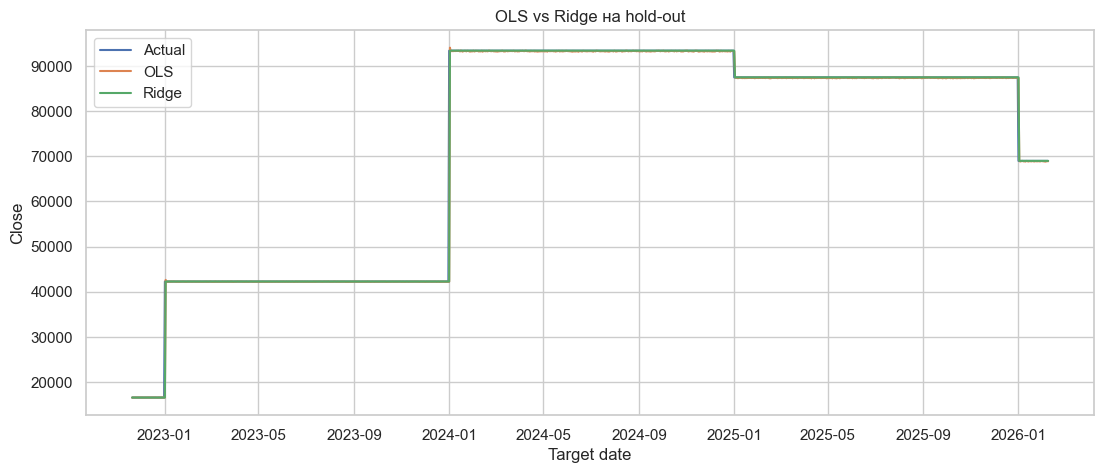

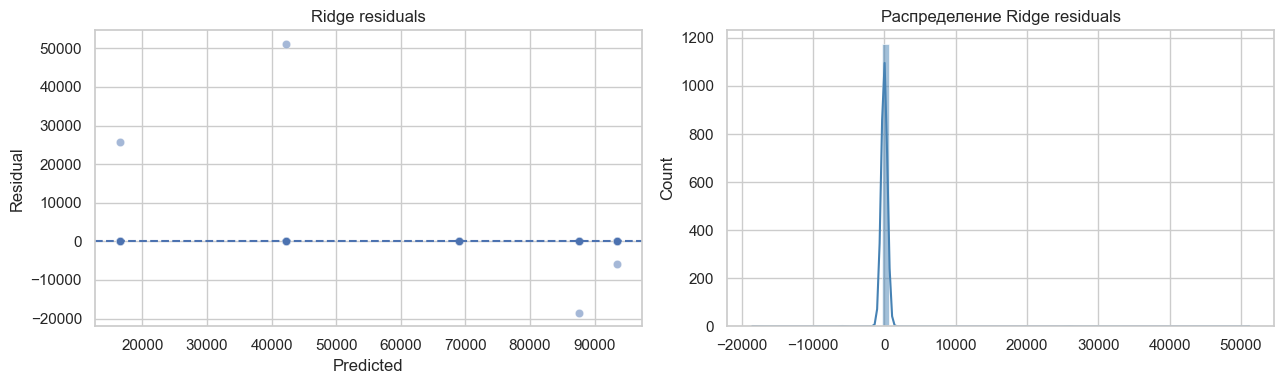

In [12]:
plot_test['Ridge'] = ridge_test_pred

plt.figure(figsize=(13, 5))
plt.plot(
    plot_test['TargetDate'],
    plot_test['Actual'],
    label='Actual'
)
plt.plot(
    plot_test['TargetDate'],
    plot_test['OLS'],
    label='OLS'
)
plt.plot(
    plot_test['TargetDate'],
    plot_test['Ridge'],
    label='Ridge'
)
plt.title('OLS vs Ridge on the hold-out period')
plt.xlabel('Target date')
plt.ylabel('Close')
plt.legend()
plt.show()

ridge_residuals = y_test.to_numpy() - ridge_test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.scatterplot(
    x=ridge_test_pred,
    y=ridge_residuals,
    alpha=0.5,
    ax=axes[0]
)
axes[0].axhline(0, linestyle='--')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Residual')
axes[0].set_title('Ridge residuals')

sns.histplot(
    ridge_residuals,
    kde=True,
    color='steelblue',
    ax=axes[1]
)
axes[1].set_title('Distribution of Ridge residuals')

plt.tight_layout()
plt.show()


### Conclusion for Part 2.3

1. Outliers are identified using the standard IQR rule on **returns**, not on the absolute Bitcoin price. This prevents normal long-term price growth from being incorrectly treated as an anomaly.
2. Outlier limits are calculated only from training data. The test set remains untouched.
3. `StandardScaler` and `Ridge` are combined inside one sklearn `Pipeline`.
4. `alpha` is selected using `TimeSeriesSplit`, so every validation period occurs after its corresponding training period.
5. OLS and Ridge are also compared on the same cleaned training data. This separates the effect of **outlier removal** from the effect of **regularization**.
6. The final judgment must be based on the actual test RMSE, MAE, and R². Ridge does not need to outperform OLS for the experiment to be valid.




## Data split

- Training predictors: **2010-01-30 — 2022-11-18**
- Training targets: **2010-01-31 — 2022-11-19**
- Test predictors: **2022-11-19 — 2026-02-07**
- Test targets: **2022-11-20 — 2026-02-08**
- Training shape: **4,676 rows × 9 predictors**
- Test shape: **1,177 rows × 9 predictors**

## OLS

- Train RMSE: **646.4393**
- Train MAE: **35.4570**
- Train R²: **0.9978**
- Test RMSE: **1765.7726**
- Test MAE: **168.8844**
- Test R²: **0.9948**

## Naive persistence baseline

Rule:

**Predicted Close tomorrow = Close today**

Results:

- Test RMSE: **1762.6309**
- Test MAE: **86.0755**
- Test R²: **0.9948**

## IQR filtering

- About **12 of 4,676** training rows were removed.
- That is approximately **0.26%** of the training observations.

## Ridge

- Best alpha: **0.0001**
- Test RMSE: **1762.6284**
- Test MAE: **86.1944**
- Test R²: **0.9948**

## Main interpretation

Ridge and the naive persistence baseline are almost identical on RMSE and R².

Ridge does **not** provide a large forecasting improvement over the simple rule:

**Tomorrow's Close ≈ Today's Close**

This is an important result:

**A very high R² does not automatically mean that a more sophisticated forecasting model adds substantial predictive value in a highly persistent time series.**
